# Retail Sales – Exploratory Data Analysis (Python)

** Business Problem: ** A retail business wants to know what drives it sales and profit: which month, categories, regions, and customer segments perform best, and whether discounts are hurting profit.

**Data: ** Simulated retail sales data (three tables: 'orders.csv', 'cutomers.csv', 'products.csv'), Jan 2024 - Dec 2025. The data is practice data created for learning and *not* from a real company.

**Steps:** 1)Load and Inspect -> 2) Clean -> 3) Merge Tables -> 4) Create new columns -> 5) Answer 5 business questions with charts -> 6) write findings.


## 1. Load and Inspect the Data


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df_cust = pd.read_csv("data/customers.csv")
df_orders = pd.read_csv("data/orders.csv")
df_products = pd.read_csv("data/products.csv")

In [5]:
# check data types missing values and duplicates
print(df_orders.dtypes,'\n')
print('Missing values in orders:\n',df_orders.isna().sum(),"\n")
print('Missing values in customers:\n', df_cust.isna().sum(),'\n')
print('duplicate order rows:\n', df_orders.duplicated().sum())
df_orders.describe()

order_id           str
order_date         str
customer_id        str
product_id         str
quantity         int64
discount       float64
ship_mode          str
sales          float64
profit         float64
dtype: object 

Missing values in orders:
 order_id         0
order_date       0
customer_id      0
product_id       0
quantity         0
discount       120
ship_mode       80
sales            0
profit           0
dtype: int64 

Missing values in customers:
 customer_id       0
customer_name     0
segment          25
region            0
city              0
dtype: int64 

duplicate order rows:
 49


,quantity,discount,sales,profit
count,4306.000000,4186.000000,4306.000000,4306.000000
mean,3.997910,0.061992,24351.094868,3198.890037
std,1.999825,0.079482,34732.111480,6610.894253
min,-1.000000,0.000000,80.000000,-21119.000000
25%,2.000000,0.000000,1740.000000,244.000000
50%,4.000000,0.050000,10507.000000,964.000000
75%,6.000000,0.100000,34020.000000,3605.000000
max,7.000000,0.300000,261800.000000,56546.000000


In [6]:
print("Orders:", df_orders.shape, "| Customers:", df_cust.shape, "| Products:", df_products.shape)
df_orders.head()

Orders: (4306, 9) | Customers: (400, 5) | Products: (80, 6)


,order_id,order_date,customer_id,product_id,quantity,discount,ship_mode,sales,profit
0,ORD-100201,2024-02-03,C0048,P047,4,0.0,Second Class,71160.0,15944.0
1,ORD-102010,2024-10-18,C0072,P060,2,0.1,Standard,828.0,206.0
2,ORD-102381,2024-01-03,C0175,P007,1,0.0,Standard,4040.0,598.0
3,ORD-100023,2025-08-26,C0276,P017,1,0.0,Standard,7720.0,864.0
4,ORD-100008,2025-08-26,C0202,P049,3,0.2,Same Day,696.0,111.0


## 2. Clean the data
Problems I am looking for: duplicate rows, missing values, dates in two different formats, inconsistent text (upper/lower case, extra spaces) and impossible values (negative quantity).

In [7]:
rows_before = len(df_orders)
print(rows_before)

4306


In [8]:
# Save the starting count
rows_before = len(df_orders)

# 1) Remove exact duplicates
df_orders = df_orders.drop_duplicates().copy()

# 2) Fix dates: most are YYYY-MM-DD, some are DD/MM/YYYY
# Note: Format changed to %Y-%m-%d and %d/%m/%Y to match your comment
iso = pd.to_datetime(df_orders['order_date'], format="%Y-%m-%d", errors='coerce')
dmy = pd.to_datetime(df_orders['order_date'], format="%d/%m/%Y", errors='coerce')
df_orders['order_date'] = iso.fillna(dmy)

# Count unreadable dates by checking the 'order_date' column, not 'order_id'
print("Dates that couldn't be read:", df_orders['order_date'].isna().sum())

# 2b) Some duplicates show up after fixing the dates
dups_id = df_orders['order_id'].duplicated().sum()
df_orders = df_orders.drop_duplicates(subset='order_id').copy()
print('Extra duplicate order IDs removed:', dups_id)

# 3) Remove impossible values (quantity must be positive)
bad_qty = (df_orders['quantity'] <= 0).sum()
df_orders = df_orders[df_orders['quantity'] > 0].copy()  # <-- Added () here

# 4) Missing values: target specific columns so you don't break the DataFrame
df_orders['discount'] = df_orders['discount'].fillna(0)
df_orders['ship_mode'] = df_orders['ship_mode'].fillna("unknown")

# 5) Clean customer text (Make sure df_cust exists in your environment!)
for col in ['customer_id', 'customer_name', 'segment', 'region', 'city']:
    df_cust[col] = df_cust[col].str.strip().str.title()

df_cust['segment'] = df_cust['segment'].fillna("unknown")

# Final summary with corrected spelling typos
print(f'Rows before: {rows_before} | after_cleaning : {len(df_orders)} | removed: {rows_before - len(df_orders)}')
print('Rows with invalid quantity removed:', bad_qty)


Dates that couldn't be read: 0
Extra duplicate order IDs removed: 11
Rows before: 4306 | after_cleaning : 4240 | removed: 66
Rows with invalid quantity removed: 6


## 3. Merge the three tables

In [9]:
df = (df_orders.merge(
        df_cust, on = "customer_id", how = "left")
        .merge(df_products, on = "product_id", how = "left"))
print('rows after merge:', len(df), "| unmatched customers:", df['region'].isna().sum(), "| unmatched product: ", df['region'].isna().sum())
df.head()

rows after merge: 4240 | unmatched customers: 0 | unmatched product:  0


,order_id,order_date,customer_id,product_id,quantity,discount,ship_mode,sales,profit,customer_name,segment,region,city,product_name,category,sub_category,list_price,unit_cost
0,ORD-100201,2024-02-03,C0048,P047,4,0.0,Second Class,71160.0,15944.0,Nikhil Nair,Corporate,West,Pune,Printer Model 7,Technology,Printers,17790,13804
1,ORD-102010,2024-10-18,C0072,P060,2,0.1,Standard,828.0,206.0,Pooja Reddy,Consumer,East,Bhubaneswar,Binder Model 4,Office Supplies,Binders,460,311
2,ORD-102381,2024-01-03,C0175,P007,1,0.0,Standard,4040.0,598.0,Kabir Kumar,Consumer,South,Bengaluru,Chair Model 7,Furniture,Chairs,4040,3442
3,ORD-100023,2025-08-26,C0276,P017,1,0.0,Standard,7720.0,864.0,Kabir Sharma,Consumer,North,Chandigarh,Bookcase Model 1,Furniture,Bookcases,7720,6856
4,ORD-100008,2025-08-26,C0202,P049,3,0.2,Same Day,696.0,111.0,Tanvi Das,Home Office,South,Kochi,Paper Model 1,Office Supplies,Paper,290,195


## 4. Create Columns

In [10]:
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.to_period("M").astype(str)
df['profit_margin']  = df['profit']/df['sales'] * 100
df['has_discount'] = df['discount'] > 0 

print("Date range:", df['order_date'].min().date(), "to", df['order_date'].max().date())
print('total sales:', round(df['sales'].sum()), '| total profit:', df['profit'].sum())
print('Overall margin: %.1f%%' % round(df['profit'].sum()/df['sales'].sum() * 100))
    
      

Date range: 2024-01-01 to 2025-12-30
total sales: 102682518 | total profit: 13446335.5
Overall margin: 13.0%


In [11]:
df

,order_id,order_date,customer_id,product_id,quantity,discount,ship_mode,sales,profit,customer_name,...,city,product_name,category,sub_category,list_price,unit_cost,year,month,profit_margin,has_discount
0,ORD-100201,2024-02-03,C0048,P047,4,0.00,Second Class,71160.0,15944.0,Nikhil Nair,...,Pune,Printer Model 7,Technology,Printers,17790,13804,2024,2024-02,22.405846,False
1,ORD-102010,2024-10-18,C0072,P060,2,0.10,Standard,828.0,206.0,Pooja Reddy,...,Bhubaneswar,Binder Model 4,Office Supplies,Binders,460,311,2024,2024-10,24.879227,True
2,ORD-102381,2024-01-03,C0175,P007,1,0.00,Standard,4040.0,598.0,Kabir Kumar,...,Bengaluru,Chair Model 7,Furniture,Chairs,4040,3442,2024,2024-01,14.801980,False
3,ORD-100023,2025-08-26,C0276,P017,1,0.00,Standard,7720.0,864.0,Kabir Sharma,...,Chandigarh,Bookcase Model 1,Furniture,Bookcases,7720,6856,2025,2025-08,11.191710,False
4,ORD-100008,2025-08-26,C0202,P049,3,0.20,Same Day,696.0,111.0,Tanvi Das,...,Kochi,Paper Model 1,Office Supplies,Paper,290,195,2025,2025-08,15.948276,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4235,ORD-102645,2025-08-05,C0070,P041,1,0.00,Second Class,19970.0,4186.0,Priya Nair,...,Patna,Printer Model 1,Technology,Printers,19970,15784,2025,2025-08,20.961442,False
4236,ORD-101356,2024-07-16,C0047,P045,5,0.05,First Class,55290.0,9400.0,Tanvi Singh,...,Hyderabad,Printer Model 5,Technology,Printers,11640,9178,2024,2024-07,17.001266,True
4237,ORD-100259,2025-03-05,C0083,P044,5,0.00,Standard,37450.0,9340.0,Riya Borah,...,Guwahati,Printer Model 4,Technology,Printers,7490,5622,2025,2025-03,24.939920,False
4238,ORD-102349,2025-09-27,C0062,P039,3,0.05,Second Class,9405.0,1389.0,Nikhil Borah,...,Guwahati,Accessorie Model 7,Technology,Accessories,3300,2672,2025,2025-09,14.768740,True


## 5. Business Questions

## Q1. How do sales change month by month

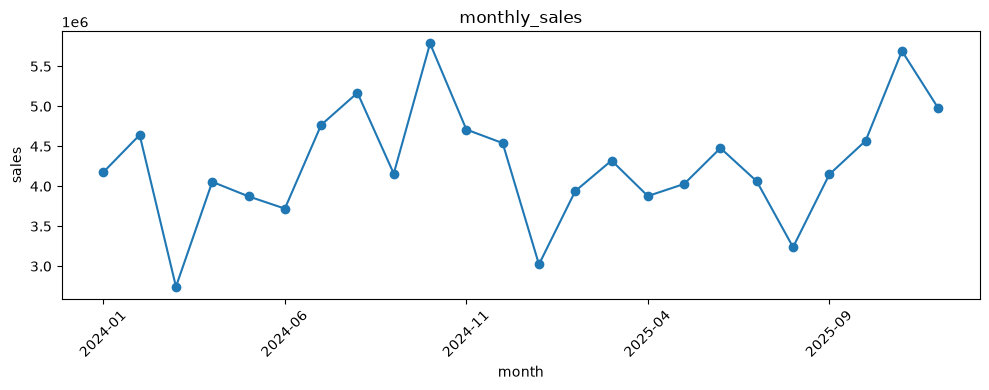

Best Month: 2024-10 | Lowest month: 2024-03


In [12]:
monthly = df.groupby('month')['sales'].sum()
monthly.plot(kind = 'line', marker = 'o', figsize = (10,4), title = 'monthly_sales')
plt.ylabel('sales');plt.xticks(rotation=45); plt.tight_layout(); plt.show()
print("Best Month:", monthly.idxmax(), "| Lowest month:", monthly.idxmin())

## Q2. Which category earns the most sales and profit?

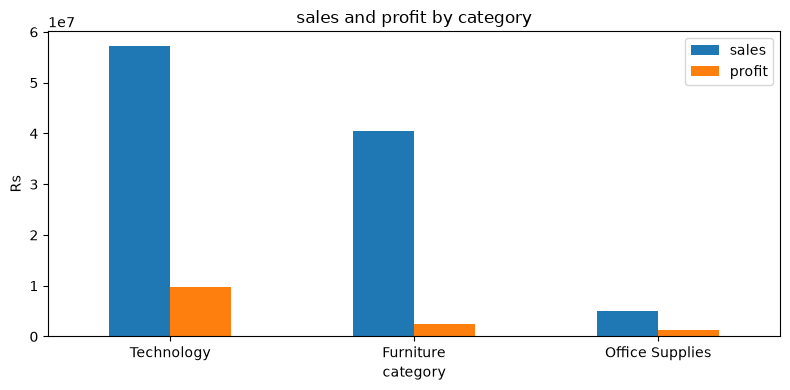

,sales,profit,margin_%
category,,,
Technology,57257664.5,9716244.5,17.0
Furniture,40481442.5,2464828.5,6.1
Office Supplies,4943410.5,1265262.5,25.6


In [13]:
cat = df.groupby('category')[['sales','profit']].sum().sort_values('sales', ascending = False)
cat['margin_%'] = (cat['profit']/cat['sales']*100).round(1)
cat[['sales','profit']].plot(kind = 'bar', figsize =(8,4), title = 'sales and profit by category')
plt.ylabel('Rs'); plt.xticks(rotation = 0); plt.tight_layout(); plt.show()
cat

## Q3. Which region and customer segment perform best?

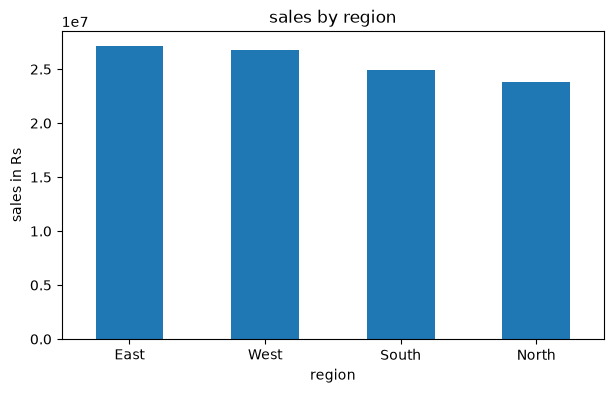

,sales,profit
segment,,
Consumer,43295707.5,5704072.5
Corporate,29110270.5,3784265.5
Home Office,24570732.5,3259318.5
unknown,5705807.0,698679.0


In [14]:
region = df.groupby('region')['sales'].sum().sort_values(ascending = False)
region.plot(kind = 'bar', figsize = (7,4), title = 'sales by region')
plt.ylabel('sales in Rs'); plt.xticks(rotation=0); plt.show()
region

segment = df.groupby('segment')[['sales','profit']].sum().sort_values('sales',ascending = False)
segment

In [15]:
region

region
East     27172858.5
West     26814132.0
South    24912260.5
North    23783266.5
Name: sales, dtype: float64

In [16]:
diff_east_west = region['East'] - region['West']
print(diff_east_west)

358726.5


## Q4. Which 10 products bring in the most profit?

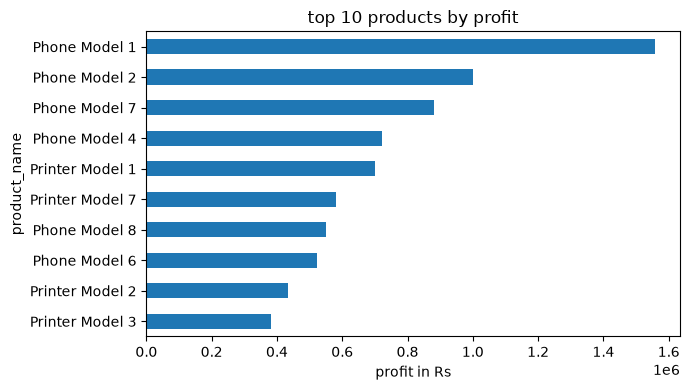

product_name
Phone Model 1      1556784.0
Phone Model 2      1000480.0
Phone Model 7       881801.0
Phone Model 4       722011.5
Printer Model 1     701479.5
Printer Model 7     580229.0
Phone Model 8       548892.0
Phone Model 6       521961.0
Printer Model 2     435026.5
Printer Model 3     382528.0
Name: profit, dtype: float64

In [17]:
top10 = df.groupby('product_name')['profit'].sum().sort_values(ascending = False).head(10)
top10.sort_values().plot(kind='barh', figsize = (7,4), title = 'top 10 products by profit')
plt.xlabel('profit in Rs'); plt.tight_layout(); plt.show()
top10


In [18]:
top10profit = top10.sum()
print(top10profit)
total_profit = df['profit'].sum()
print(total_profit)
profitpct = (top10profit/total_profit*100)
print(profitpct)

7331192.5
13446335.5
54.52186210882511


## Q5. Do higher discounts reduce profit margin?

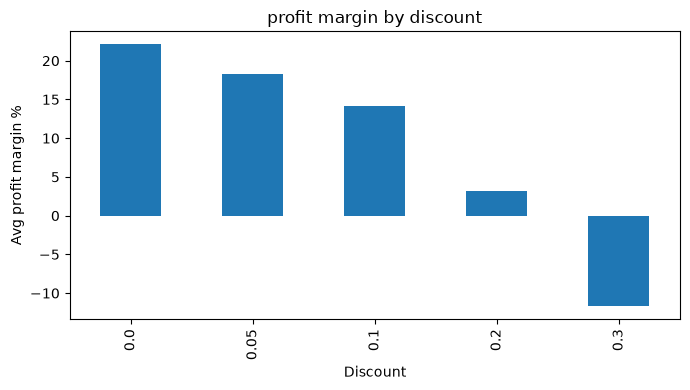

discount
0.00    22.1
0.05    18.3
0.10    14.2
0.20     3.2
0.30   -11.7
Name: profit_margin, dtype: float64

In [19]:
profit = df.groupby('discount')['profit_margin'].mean().round(1)
profit.plot(kind = 'bar', figsize=(7,4), title = 'profit margin by discount')
plt.xlabel('Discount'); plt.ylabel('Avg profit margin %'); plt.tight_layout(); plt.show()
profit

## 6. Save the cleaned data used for Power BI and SQL 

In [20]:
df.to_csv("cleaned_sales_data.csv",index = False)  # one flat table for Power BI
df_cust.to_csv("customers_clean.csv", index = False) # clean tables for SQL
df_orders.to_csv("orders_clean.csv", index = False)
print("saved cleaned_sales_data.csv with ", len(df),"rows, plus orders_clean.csv and customers_clean.csv")


saved cleaned_sales_data.csv with  4240 rows, plus orders_clean.csv and customers_clean.csv


## 7. Key findings

# Write each finding in your own words after you run the notebook, using the real numbers from your outputs above.
Trend: Sales are highest in October 2024 and lowest in March 2024; Oct–Dec is stronger than the rest of the year.
Category: Technology brings the most sales, but office supplies has the best profit margin of 25.6%.
Region and segment: East region leads with ₹358726.5;  Consumer segment contributes ___%.
Products: The top 10 products give 54.52% of total profit.
Discounts: Margin falls from 22.1% at no discount to -11.7% at 30% discount.
**Recommendation:** Sales are highest between Oct-Dec, so have enough staff for the period and around March, can have lean staff. Technology products sell well, however office supplies has the best profit margin. So, invest more in office supplies. We should do more market research for the other regions and find out what worked well for the east region. Should pay more attention on the top 10 products that accounts to 54.52% profit margin. Discounts actually affects the profit.  